In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Datasets/ushape.csv')

In [3]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


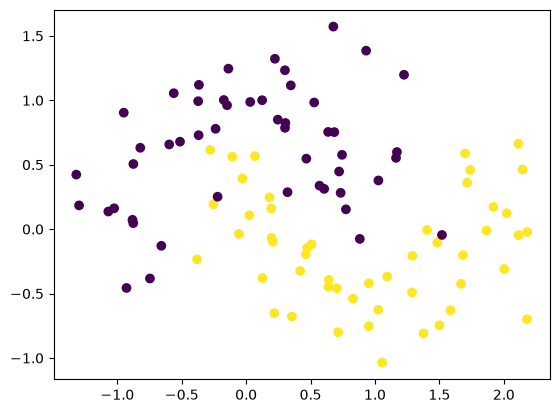

In [4]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [5]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [6]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [7]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.summary()

C:\Users\Rihan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 10)                  │              30 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 41 (164.00 B)

 Trainable params: 41 (164.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Set parameters to 0
model.get_weights()

[array([[ 0.42907006, -0.5245179 ,  0.0465706 , -0.25593185, -0.5948122 ,
         -0.09193945,  0.16958928, -0.5624662 ,  0.6471402 ,  0.62824327],
        [ 0.22806889,  0.27013433, -0.6401107 , -0.1371094 ,  0.25320172,
         -0.57065535, -0.5227145 ,  0.6158988 , -0.33558652,  0.40025753]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.40965194],
        [-0.2930855 ],
        [ 0.5218609 ],
        [ 0.41449732],
        [ 0.05833584],
        [-0.6786516 ],
        [-0.52188504],
        [ 0.12718195],
        [-0.12440425],
        [-0.40605855]], dtype=float32),
 array([0.], dtype=float32)]

In [9]:
initial_weights = model.get_weights()

In [10]:
initial_weights[0] = np.ones(model.get_weights()[0].shape)
initial_weights[1] = np.ones(model.get_weights()[1].shape)
initial_weights[2] = np.ones(model.get_weights()[2].shape)
initial_weights[3] = np.ones(model.get_weights()[3].shape)

In [11]:
model.set_weights(initial_weights)

In [12]:
model.get_weights()

[array([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]], dtype=float32),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32),
 array([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.]], dtype=float32),
 array([1.], dtype=float32)]

In [13]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [14]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 237ms/step - accuracy: 0.5000 - loss: 9.4173 - val_accuracy: 0.5000 - val_loss: 6.5085
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5000 - loss: 9.3640 - val_accuracy: 0.5000 - val_loss: 6.4716
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5000 - loss: 9.3113 - val_accuracy: 0.5000 - val_loss: 6.4348
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5000 - loss: 9.2589 - val_accuracy: 0.5000 - val_loss: 6.3982
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5000 - loss: 9.2067 - val_accuracy: 0.5000 - val_loss: 6.3617
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5000 - loss: 9.1546 - val_accuracy: 0.5000 - val_loss: 6.3254
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5000 - loss: 9.1028 - val_accuracy: 0.5000 - val_loss: 6.2893
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5000 - loss: 9.0512 - val_accuracy: 0.5000 - val_loss

In [15]:
model.get_weights()

[array([[0.79252076, 0.79252076, 0.79252076, 0.79252076, 0.79252076,
         0.79252076, 0.79252076, 0.79252076, 0.79252076, 0.79252076],
        [0.7302238 , 0.7302238 , 0.7302238 , 0.7302238 , 0.7302238 ,
         0.7302238 , 0.7302238 , 0.7302238 , 0.7302238 , 0.7302238 ]],
       dtype=float32),
 array([0.72529286, 0.72529286, 0.72529286, 0.72529286, 0.72529286,
        0.72529286, 0.72529286, 0.72529286, 0.72529286, 0.72529286],
       dtype=float32),
 array([[0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642],
        [0.7307642]], dtype=float32),
 array([0.70705724], dtype=float32)]

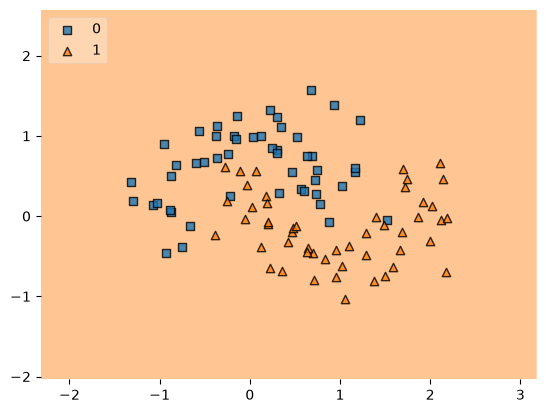

In [16]:
from mlxtend.plotting import plot_decision_regions
import numpy as np
import matplotlib.pyplot as plt

class Wrapper:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        return (self.model.predict(X, verbose=0).ravel() >= 0.5).astype(int)

plot_decision_regions(
    np.asarray(X, dtype=float),
    np.asarray(y).ravel().astype(int),
    clf=Wrapper(model),
    legend=2
)
plt.show()